In [2]:
import os
import re
import gc
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

import librosa
import soundfile as sf

from tqdm.auto import tqdm

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU count:", torch.cuda.device_count())
    
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [4]:
!nvidia-smi

Wed Oct  7 14:44:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Locate the Dataset

In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)

    for file in files[:10]:
        print("   ", file)

/kaggle/input
/kaggle/input/competitions
/kaggle/input/competitions/shl-hiring-assessment-2026
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final
    sample_submission.csv
    train.csv
    test.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test
    audio_49.wav
    audio_90.wav
    audio_77.wav
    audio_66.wav
    audio_54.wav
    audio_42.wav
    audio_81.wav
    audio_72.wav
    audio_107.wav
    audio_79.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train
    audio_49.wav
    audio_663.wav
    audio_5059.wav
    audio_90.wav
    audio_581.wav
    audio_698.wav
    audio_77.wav
    audio_66.wav
    audio_555.wav
    audio_54.wav


## 1. Load Dataset

The dataset contains 769 labeled training audio samples and 216 test audio samples.

The training CSV contains the actual grammar scores. The test CSV contains `-1` as a placeholder score, which will not be used as a target.

In [6]:
import os
import numpy as np
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"

TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
TEST_CSV = os.path.join(DATA_DIR, "test.csv")
SAMPLE_CSV = os.path.join(DATA_DIR, "sample_submission.csv")

TRAIN_AUDIO_DIR = os.path.join(DATA_DIR, "train")
TEST_AUDIO_DIR = os.path.join(DATA_DIR, "test")

train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
sample_submission = pd.read_csv(SAMPLE_CSV)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

Train shape: (769, 2)
Test shape: (216, 2)
Sample submission shape: (204, 2)


# Inspect the CSV structure

In [7]:
print("TRAIN COLUMNS")
print(train.columns.tolist())

print("\nTEST COLUMNS")
print(test.columns.tolist())

print("\nSUBMISSION COLUMNS")
print(sample_submission.columns.tolist())

TRAIN COLUMNS
['filename', 'label']

TEST COLUMNS
['filename', 'label']

SUBMISSION COLUMNS
['filename', 'label']


In [8]:
print("TRAIN")
display(train.head())

print("\nTEST")
display(test.head())

print("\nSAMPLE SUBMISSION")
display(sample_submission.head())

TRAIN


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0



TEST


,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1



SAMPLE SUBMISSION


,filename,label
0,audio_804.wav,-1
1,audio_1028.wav,-1
2,audio_865.wav,-1
3,audio_774.wav,-1
4,audio_1138.wav,-1


# Inspect data types and Missing Values

In [9]:
print("Training information:")
train.info()

print("\nMissing values in training:")
print(train.isnull().sum())

print("\nMissing values in test:")
print(test.isnull().sum())

Training information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 769 entries, 0 to 768
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   filename  769 non-null    object 
 1   label     769 non-null    float64
dtypes: float64(1), object(1)
memory usage: 12.1+ KB

Missing values in training:
filename    0
label       0
dtype: int64

Missing values in test:
filename    0
label       0
dtype: int64


In [10]:
print(train.describe(include="all"))

             filename       label
count             769  769.000000
unique            769         NaN
top     audio_691.wav         NaN
freq                1         NaN
mean              NaN    3.313394
std               NaN    1.239000
min               NaN    0.000000
25%               NaN    2.500000
50%               NaN    3.000000
75%               NaN    4.000000
max               NaN    5.000000


In [11]:
AUDIO_COL = "filename"
TARGET_COL = "label"

In [12]:
print("Audio column:", AUDIO_COL)
print("Target column:", TARGET_COL)

print("\nTarget statistics:")
print(train[TARGET_COL].describe())

Audio column: filename
Target column: label

Target statistics:
count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


# Verify the Grammar Scores

In [13]:
print("Unique training scores:")
print(sorted(train[TARGET_COL].unique()))

print("\nScore distribution:")
print(train[TARGET_COL].value_counts().sort_index())
print("Test score values:")
print(test[TARGET_COL].unique())

Unique training scores:
[np.float64(0.0), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]

Score distribution:
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64
Test score values:
[-1]


# Grammar Score Distribution

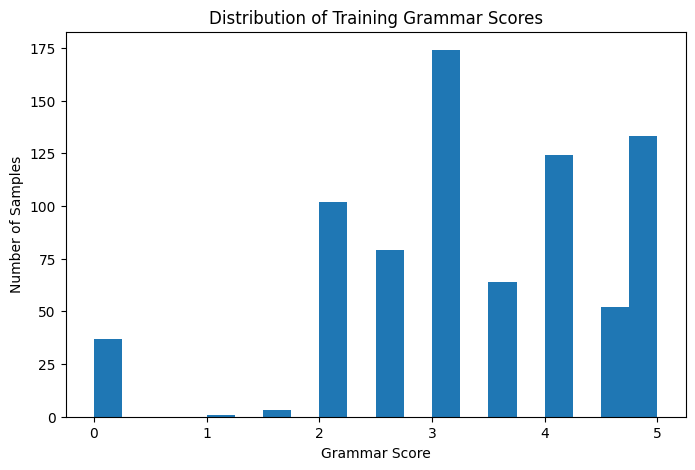

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    train[TARGET_COL],
    bins=20
)

plt.xlabel("Grammar Score")
plt.ylabel("Number of Samples")
plt.title("Distribution of Training Grammar Scores")

plt.show()

# Verify the audio folders

In [15]:
train_audio_files = [
    f for f in os.listdir(TRAIN_AUDIO_DIR)
    if f.lower().endswith(".wav")
]

test_audio_files = [
    f for f in os.listdir(TEST_AUDIO_DIR)
    if f.lower().endswith(".wav")
]

print("Training WAV files:", len(train_audio_files))
print("Testing WAV files:", len(test_audio_files))

print("\nFirst 10 training files:")
print(train_audio_files[:10])

print("\nFirst 10 testing files:")
print(test_audio_files[:10])

Training WAV files: 769
Testing WAV files: 216

First 10 training files:
['audio_49.wav', 'audio_663.wav', 'audio_5059.wav', 'audio_90.wav', 'audio_581.wav', 'audio_698.wav', 'audio_77.wav', 'audio_66.wav', 'audio_555.wav', 'audio_54.wav']

First 10 testing files:
['audio_49.wav', 'audio_90.wav', 'audio_77.wav', 'audio_66.wav', 'audio_54.wav', 'audio_42.wav', 'audio_81.wav', 'audio_72.wav', 'audio_107.wav', 'audio_79.wav']


# Verify CSV <-> Audio Mapping

In [16]:
train_audio_set = set(train_audio_files)
test_audio_set = set(test_audio_files)

missing_train = [
    f for f in train[AUDIO_COL]
    if f not in train_audio_set
]

missing_test = [
    f for f in test[AUDIO_COL]
    if f not in test_audio_set
]

print("Missing training audio:", len(missing_train))
print("Missing testing audio:", len(missing_test))

if missing_train:
    print("Examples:", missing_train[:10])

if missing_test:
    print("Examples:", missing_test[:10])

Missing training audio: 0
Missing testing audio: 0


## Creating full audio paths

In [17]:
train["audio_path"] = train[AUDIO_COL].apply(
    lambda x: os.path.join(TRAIN_AUDIO_DIR, x)
)

test["audio_path"] = test[AUDIO_COL].apply(
    lambda x: os.path.join(TEST_AUDIO_DIR, x)
)

print(train[["audio_path", TARGET_COL]].head())

                                          audio_path  label
0  /kaggle/input/competitions/shl-hiring-assessme...    3.0
1  /kaggle/input/competitions/shl-hiring-assessme...    3.0
2  /kaggle/input/competitions/shl-hiring-assessme...    3.5
3  /kaggle/input/competitions/shl-hiring-assessme...    2.0
4  /kaggle/input/competitions/shl-hiring-assessme...    2.0


In [18]:
print(
    "All training paths exist:",
    train["audio_path"].apply(os.path.exists).all()
)

print(
    "All testing paths exist:",
    test["audio_path"].apply(os.path.exists).all()
)

All training paths exist: True
All testing paths exist: True


# Load and Inspect Audio

In [19]:
!pip install -q librosa soundfile

In [20]:
sample_path = train.iloc[0]["audio_path"]

audio, sr = librosa.load(
    sample_path,
    sr=None,
    mono=True
)

print("Audio file:", sample_path)
print("Sample rate:", sr)
print("Number of samples:", len(audio))
print("Duration:", len(audio) / sr, "seconds")

Audio file: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_192.wav
Sample rate: 16000
Number of samples: 968134
Duration: 60.508375 seconds


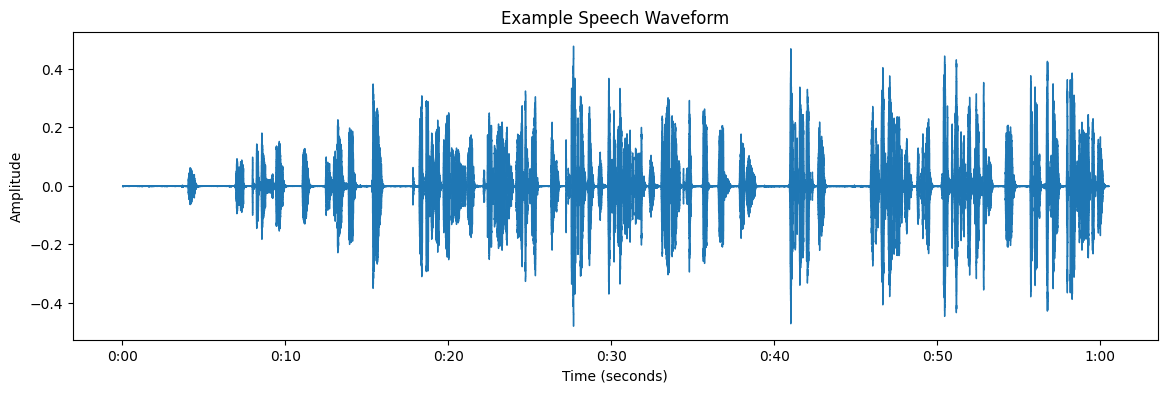

In [21]:
plt.figure(figsize=(14, 4))

librosa.display.waveshow(
    audio,
    sr=sr
)

plt.title("Example Speech Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

# Check all Audio Durations.

In [22]:
from tqdm.auto import tqdm

durations = []

for path in tqdm(
    train["audio_path"],
    desc="Checking audio durations"
):
    try:
        duration = librosa.get_duration(path=path)
        durations.append(duration)
    except Exception:
        durations.append(np.nan)

train["duration"] = durations

print(train["duration"].describe())

Checking audio durations:   0%|          | 0/769 [00:00<?, ?it/s]

count    769.000000
mean      55.781067
std        7.908964
min       20.060000
25%       54.186687
50%       60.074688
75%       60.074688
max       61.040000
Name: duration, dtype: float64


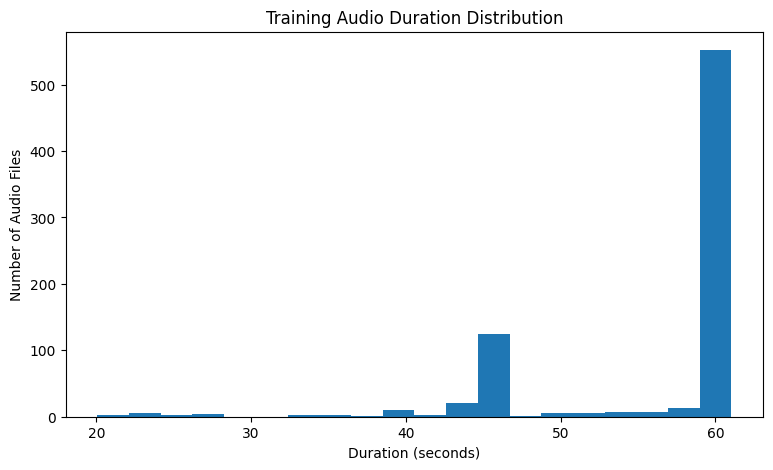

In [23]:
plt.figure(figsize=(9, 5))

plt.hist(
    train["duration"].dropna(),
    bins=20
)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Audio Files")
plt.title("Training Audio Duration Distribution")

plt.show()

In [24]:
sample_rates = []

for path in tqdm(
    train["audio_path"],
    desc="Checking sample rates"
):
    try:
        info = sf.info(path)
        sample_rates.append(info.samplerate)
    except:
        sample_rates.append(np.nan)

train["sample_rate"] = sample_rates

print(train["sample_rate"].value_counts())

Checking sample rates:   0%|          | 0/769 [00:00<?, ?it/s]

sample_rate
16000    769
Name: count, dtype: int64


In [25]:
AUDIO_COL = "filename"
TARGET_COL = "label"

train["audio_path"] = train[AUDIO_COL].apply(
    lambda x: os.path.join(TRAIN_AUDIO_DIR, x)
)

test["audio_path"] = test[AUDIO_COL].apply(
    lambda x: os.path.join(TEST_AUDIO_DIR, x)
)

display(train.head())

,filename,label,audio_path,duration,sample_rate
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.508375,16000
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,16000
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...,60.074688,16000
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.060000,16000
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...,45.300000,16000


In [26]:
train.to_csv(
    "/kaggle/working/train_metadata.csv",
    index=False
)

test.to_csv(
    "/kaggle/working/test_metadata.csv",
    index=False
)

print("Metadata saved.")

Metadata saved.


# Create our validation strategy.

In [27]:
from sklearn.model_selection import KFold

N_SPLITS = 5
RANDOM_STATE = 42

kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("5-fold cross-validation configured.")

5-fold cross-validation configured.


In [28]:
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

def evaluate_predictions(y_true, y_pred):
    
    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )
    
    pearson = pearsonr(
        y_true,
        y_pred
    )[0]
    
    return rmse, pearson

# Actual ML Pipeline

In [29]:
!pip install -q openai-whisper sentence-transformers lightgbm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 12.0 MB/s eta 0:00:00a 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [30]:
import os
import re
import json
import pickle
import warnings

import numpy as np
import pandas as pd

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

In [31]:
import torch
import whisper

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

whisper_model = whisper.load_model(
    "small.en",
    device=DEVICE
)

print("Whisper loaded.")

Device: cuda


100%|███████████████████████████████████████| 461M/461M [00:06<00:00, 78.0MiB/s]


Whisper loaded.


# Create Transcription Function

In [32]:
def transcribe_audio(audio_path):
    
    result = whisper_model.transcribe(
        audio_path,
        language="en",
        fp16=(DEVICE == "cuda"),
        temperature=0,
        condition_on_previous_text=False,
        verbose = False
    )
    
    return result["text"].strip()

In [33]:
sample_text = transcribe_audio(
    train.iloc[0]["audio_path"]
)

print(sample_text)

100%|██████████| 6050/6050 [00:03<00:00, 1514.55frames/s]

The playground is very, very beautiful and fun. There are, there are playthings like the merry-go-round, the swing. The students usually enjoy this swing. it has to be like, it's more like a gimbal space. Once it's finished and the other person will have to finish, and the mirror goes around, which is fine for me. And most of them play for the fall. On sand parks, while others just keep the swing, of the kid like she viewed sound of questions and most times you hear the sound of screaming children laughing kids.


# Transcribe the training data.

In [34]:
TRAIN_TRANSCRIPT_FILE = "/kaggle/working/train_transcripts.csv"

if os.path.exists(TRAIN_TRANSCRIPT_FILE):
    
    train_transcripts = pd.read_csv(
        TRAIN_TRANSCRIPT_FILE
    )
    
    print("Loaded cached transcripts.")
    
else:
    
    train_transcripts = train.copy()
    train_transcripts["transcript"] = ""
    
    for i in tqdm(
        range(len(train_transcripts)),
        desc="Transcribing training audio"
    ):
        
        try:
            train_transcripts.loc[i, "transcript"] = (
                transcribe_audio(
                    train_transcripts.loc[i, "audio_path"]
                )
            )
            
        except Exception as e:
            print(
                f"Error at index {i}: {e}"
            )
            
            train_transcripts.loc[i, "transcript"] = ""
        
        # Save every 25 files
        if (i + 1) % 25 == 0:
            train_transcripts.to_csv(
                TRAIN_TRANSCRIPT_FILE,
                index=False
            )

    train_transcripts.to_csv(
        TRAIN_TRANSCRIPT_FILE,
        index=False
    )

print(
    "Training transcripts:",
    len(train_transcripts)
)

Transcribing training audio:   0%|          | 0/769 [00:00<?, ?it/s]


100%|██████████| 6050/6050 [00:02<00:00, 2461.83frames/s]

100%|██████████| 6007/6007 [00:02<00:00, 2244.86frames/s]

 97%|█████████▋| 5856/6007 [00:03<00:00, 1756.33frames/s]

100%|██████████| 4506/4506 [00:02<00:00, 2163.28frames/s]

100%|██████████| 4530/4530 [00:01<00:00, 2527.50frames/s]

 50%|█████     | 3007/6007 [00:01<00:01, 2057.13frames/s]

100%|██████████| 5216/5216 [00:02<00:00, 2439.75frames/s]

100%|██████████| 6007/6007 [00:02<00:00, 2036.04frames/s]

100%|██████████| 6007/6007 [00:02<00:00, 2296.32frames/s]

100%|██████████| 6007/6007 [00:02<00:00, 2501.53frames/s]

100%|██████████| 6007/6007 [00:02<00:00, 2243.88frames/s]

100%|██████████| 6007/6007 [00:02<00:00, 2261.70frames/s]

100%|██████████| 6007/6007 [00:01<00:00, 3297.83frames/s]

100%|██████████| 6007/6007 [00:02<00:00, 2810.11frames/s]

100%|██████████| 6007/6007 [00:02<00:00, 2047.42frames/s]

100%|██████████| 4506/4506 [00:01<00:00, 2611.71frames/s]

100%|██████████| 2653/2653 [00:01<00:00, 2246.08frames/

Training transcripts: 769


In [35]:
TEST_TRANSCRIPT_FILE = "/kaggle/working/test_transcripts.csv"

if os.path.exists(TEST_TRANSCRIPT_FILE):
    
    test_transcripts = pd.read_csv(
        TEST_TRANSCRIPT_FILE
    )
    
    print("Loaded cached test transcripts.")
    
else:
    
    test_transcripts = test.copy()
    test_transcripts["transcript"] = ""
    
    for i in tqdm(
        range(len(test_transcripts)),
        desc="Transcribing test audio"
    ):
        
        try:
            test_transcripts.loc[i, "transcript"] = (
                transcribe_audio(
                    test_transcripts.loc[i, "audio_path"]
                )
            )
            
        except Exception as e:
            print(
                f"Error at index {i}: {e}"
            )
            
            test_transcripts.loc[i, "transcript"] = ""
        
        if (i + 1) % 25 == 0:
            test_transcripts.to_csv(
                TEST_TRANSCRIPT_FILE,
                index=False
            )

    test_transcripts.to_csv(
        TEST_TRANSCRIPT_FILE,
        index=False
    )

print(
    "Test transcripts:",
    len(test_transcripts)
)

Transcribing test audio:   0%|          | 0/216 [00:00<?, ?it/s]


 99%|█████████▉| 4452/4506 [00:02<00:00, 1901.19frames/s]

100%|██████████| 4496/4496 [00:01<00:00, 2780.94frames/s]

100%|██████████| 4501/4501 [00:02<00:00, 1762.55frames/s]

100%|██████████| 5898/5898 [00:01<00:00, 4467.60frames/s]

100%|██████████| 4504/4504 [00:01<00:00, 2362.95frames/s]

100%|██████████| 4506/4506 [00:02<00:00, 2119.19frames/s]

100%|██████████| 4484/4484 [00:02<00:00, 1890.35frames/s]

100%|██████████| 4506/4506 [00:01<00:00, 2992.40frames/s]

100%|██████████| 4506/4506 [00:01<00:00, 2683.27frames/s]

100%|██████████| 4486/4486 [00:02<00:00, 2156.71frames/s]

100%|██████████| 6008/6008 [00:02<00:00, 2010.84frames/s]

100%|██████████| 4506/4506 [00:01<00:00, 2788.71frames/s]

100%|██████████| 4506/4506 [00:02<00:00, 2241.53frames/s]

100%|██████████| 1856/1856 [00:00<00:00, 2332.56frames/s]

100%|██████████| 6008/6008 [00:02<00:00, 2117.30frames/s]

100%|██████████| 4470/4470 [00:02<00:00, 1517.94frames/s]

100%|██████████| 4599/4599 [00:02<00:00, 2050.44frames/

Test transcripts: 216


# Check Transcription Quality

In [36]:
display(
    train_transcripts[
        [AUDIO_COL, TARGET_COL, "transcript"]
    ].head(10)
)

,filename,label,transcript
0,audio_192.wav,3.0,"The playground is very, very beautiful and fun..."
1,audio_436.wav,3.0,"The scene of a school playground, our playgrou..."
2,audio_447.wav,3.5,My favorite place to visit is the beach. I lov...
3,audio_126.wav,2.0,Once upon a time we with 5 friends went on a t...
4,audio_61.wav,2.0,"Well, when I was a child, I remember I went to..."
5,audio_639.wav,2.5,The best thing of my life was probably when I ...
6,audio_703.wav,2.0,I know you've known several. No. No. The first...
7,audio_509.wav,3.0,"smoothing effect. Besides this, I also have ho..."
8,audio_672.wav,4.0,The school playground is very big and is very ...
9,audio_344.wav,4.0,My number one goal in life is to become the be...


In [37]:
empty_train = (
    train_transcripts["transcript"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

empty_test = (
    test_transcripts["transcript"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

print("Empty train transcripts:", empty_train)
print("Empty test transcripts:", empty_test)

Empty train transcripts: 1
Empty test transcripts: 0


In [38]:
# Retry any empty training transcripts

empty_indices = train_transcripts[
    train_transcripts["transcript"]
    .fillna("")
    .str.strip()
    .eq("")
].index

print("Empty transcripts before retry:", len(empty_indices))

for idx in empty_indices:

    path = train_transcripts.loc[
        idx,
        "audio_path"
    ]

    try:
        text = transcribe_audio(path)

        train_transcripts.loc[
            idx,
            "transcript"
        ] = text

    except Exception as e:
        print(f"Error at index {idx}: {e}")

print(
    "Empty transcripts after retry:",
    train_transcripts["transcript"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

Empty transcripts before retry: 1


  0%|          | 0/6008 [00:01<?, ?frames/s]

Empty transcripts after retry: 1


In [39]:
train_transcripts.to_csv(
    TRAIN_TRANSCRIPT_FILE,
    index=False
)

In [40]:
!pip install -q spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 80.0 MB/s eta 0:00:0000:010:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [41]:
# Linguistic Grammar Features
import spacy

nlp = spacy.load(
    "en_core_web_sm",
    disable=["ner"]
)

## Feature extraction Function

In [42]:
def extract_linguistic_features(text):
    
    text = str(text)
    
    doc = nlp(text)
    
    tokens = [
        token for token in doc
        if not token.is_space
    ]
    
    words = [
        token for token in tokens
        if token.is_alpha
    ]
    
    sentences = list(doc.sents)
    
    n_words = len(words)
    n_sentences = len(sentences)
    
    if n_words == 0:
        return {
            "num_words": 0,
            "num_sentences": 0,
            "avg_sentence_length": 0,
            "sentence_length_std": 0,
            "unique_word_ratio": 0,
            "avg_word_length": 0,
            "noun_ratio": 0,
            "verb_ratio": 0,
            "adj_ratio": 0,
            "adv_ratio": 0,
            "pronoun_ratio": 0,
            "prep_ratio": 0,
            "conj_ratio": 0,
            "det_ratio": 0,
            "aux_ratio": 0,
            "punct_ratio": 0,
            "subordinate_ratio": 0,
            "question_ratio": 0,
            "exclamation_ratio": 0,
            "avg_dependency_depth": 0
        }
    
    sentence_lengths = [
        len([
            token for token in sent
            if token.is_alpha
        ])
        for sent in sentences
    ]
    
    pos_counts = {}
    
    for token in words:
        pos_counts[token.pos_] = (
            pos_counts.get(token.pos_, 0) + 1
        )
    
    # Dependency depth
    depths = []
    
    for token in words:
        
        depth = 0
        current = token
        
        while current.head != current:
            depth += 1
            current = current.head
            
            if depth > 20:
                break
        
        depths.append(depth)
    
    text_lower = text.lower()
    
    question_count = text.count("?")
    exclamation_count = text.count("!")
    
    return {
        
        "num_words": n_words,
        
        "num_sentences": n_sentences,
        
        "avg_sentence_length":
            np.mean(sentence_lengths)
            if sentence_lengths else 0,
        
        "sentence_length_std":
            np.std(sentence_lengths)
            if sentence_lengths else 0,
        
        "unique_word_ratio":
            len(
                set(
                    token.text.lower()
                    for token in words
                )
            ) / n_words,
        
        "avg_word_length":
            np.mean([
                len(token.text)
                for token in words
            ]),
        
        "noun_ratio":
            pos_counts.get("NOUN", 0) / n_words,
        
        "verb_ratio":
            pos_counts.get("VERB", 0) / n_words,
        
        "adj_ratio":
            pos_counts.get("ADJ", 0) / n_words,
        
        "adv_ratio":
            pos_counts.get("ADV", 0) / n_words,
        
        "pronoun_ratio":
            pos_counts.get("PRON", 0) / n_words,
        
        "prep_ratio":
            pos_counts.get("ADP", 0) / n_words,
        
        "conj_ratio":
            pos_counts.get("CCONJ", 0) / n_words,
        
        "det_ratio":
            pos_counts.get("DET", 0) / n_words,
        
        "aux_ratio":
            pos_counts.get("AUX", 0) / n_words,
        
        "punct_ratio":
            sum(
                token.is_punct
                for token in tokens
            ) / max(len(tokens), 1),
        
        "subordinate_ratio":
            sum(
                token.dep_ in [
                    "advcl",
                    "ccomp",
                    "xcomp",
                    "acl",
                    "relcl"
                ]
                for token in words
            ) / n_words,
        
        "question_ratio":
            question_count / max(n_sentences, 1),
        
        "exclamation_ratio":
            exclamation_count / max(n_sentences, 1),
        
        "avg_dependency_depth":
            np.mean(depths)
            if depths else 0
    }

# Extract features

In [43]:
train_ling = pd.DataFrame(
    train_transcripts["transcript"]
    .fillna("")
    .apply(extract_linguistic_features)
    .tolist()
)

test_ling = pd.DataFrame(
    test_transcripts["transcript"]
    .fillna("")
    .apply(extract_linguistic_features)
    .tolist()
)

print("Train linguistic features:", train_ling.shape)
print("Test linguistic features:", test_ling.shape)

Train linguistic features: (769, 20)
Test linguistic features: (216, 20)


In [44]:
train_ling.to_csv(
    "/kaggle/working/train_linguistic_features.csv",
    index=False
)

test_ling.to_csv(
    "/kaggle/working/test_linguistic_features.csv",
    index=False
)

In [45]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Sentence Embeddings

In [46]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [47]:
train_embeddings = embedding_model.encode(
    train_transcripts["transcript"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

test_embeddings = embedding_model.encode(
    test_transcripts["transcript"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)

print(train_embeddings.shape)
print(test_embeddings.shape)

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

(769, 384)
(216, 384)


In [48]:
np.save(
    "/kaggle/working/train_embeddings.npy",
    train_embeddings
)

np.save(
    "/kaggle/working/test_embeddings.npy",
    test_embeddings
)

### Prepare target

In [49]:
y = train_transcripts[TARGET_COL].astype(float).values

print("Target shape:", y.shape)
print("Min:", y.min())
print("Max:", y.max())
print("Mean:", y.mean())

Target shape: (769,)
Min: 0.0
Max: 5.0
Mean: 3.3133940182054618


In [50]:
### Evaluation Function
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

def calculate_metrics(y_true, y_pred):
    
    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )
    
    pearson = pearsonr(
        y_true,
        y_pred
    )[0]
    
    return rmse, pearson

## LightGBM Model

In [51]:
from lightgbm import LGBMRegressor

def create_lgbm():
    
    return LGBMRegressor(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=15,
        max_depth=5,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        verbosity=-1
    )

## CV using linguistic features + embeddings

In [52]:
from sklearn.model_selection import KFold

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_lgbm = np.zeros(len(train_transcripts))

fold_results = []

for fold, (train_idx, valid_idx) in enumerate(
    kf.split(train_transcripts),
    start=1
):
    
    print(f"\n========== Fold {fold} ==========")
    
    X_train_ling = train_ling.iloc[
        train_idx
    ].values
    
    X_valid_ling = train_ling.iloc[
        valid_idx
    ].values
    
    X_train_emb = train_embeddings[
        train_idx
    ]
    
    X_valid_emb = train_embeddings[
        valid_idx
    ]
    
    X_train = np.hstack([
        X_train_ling,
        X_train_emb
    ])
    
    X_valid = np.hstack([
        X_valid_ling,
        X_valid_emb
    ])
    
    y_train = y[train_idx]
    y_valid = y[valid_idx]
    
    model = create_lgbm()
    
    model.fit(
        X_train,
        y_train
    )
    
    pred = model.predict(
        X_valid
    )
    
    pred = np.clip(
        pred,
        0,
        5
    )
    
    oof_lgbm[valid_idx] = pred
    
    rmse, pearson = calculate_metrics(
        y_valid,
        pred
    )
    
    fold_results.append(
        [fold, rmse, pearson]
    )
    
    print(
        f"RMSE: {rmse:.4f}"
    )
    
    print(
        f"Pearson: {pearson:.4f}"
    )


========== Fold 1 ==========
RMSE: 1.1527
Pearson: 0.5375

========== Fold 2 ==========
RMSE: 0.9394
Pearson: 0.6501

========== Fold 3 ==========
RMSE: 1.0044
Pearson: 0.5327

========== Fold 4 ==========
RMSE: 1.0206
Pearson: 0.5702

========== Fold 5 ==========
RMSE: 0.9042
Pearson: 0.6496


In [53]:
## OOF score
overall_rmse, overall_pearson = calculate_metrics(
    y,
    oof_lgbm
)

print("\n==============================")
print("LIGHTGBM OOF RESULTS")
print("==============================")

print(
    f"RMSE:    {overall_rmse:.4f}"
)

print(
    f"Pearson: {overall_pearson:.4f}"
)


LIGHTGBM OOF RESULTS
RMSE:    1.0080
Pearson: 0.5827


## TF-IDF + Ridge Model

In [54]:
from sklearn.linear_model import Ridge
from scipy.sparse import hstack

In [55]:
oof_ridge = np.zeros(len(train_transcripts))

ridge_results = []

for fold, (train_idx, valid_idx) in enumerate(
    kf.split(train_transcripts),
    start=1
):
    
    print(f"\n========== Fold {fold} ==========")
    
    train_text = train_transcripts.iloc[
        train_idx
    ]["transcript"].fillna("")
    
    valid_text = train_transcripts.iloc[
        valid_idx
    ]["transcript"].fillna("")
    
    word_vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=15000,
        sublinear_tf=True
    )
    
    char_vectorizer = TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        max_features=10000,
        sublinear_tf=True
    )
    
    X_train_word = word_vectorizer.fit_transform(
        train_text
    )
    
    X_valid_word = word_vectorizer.transform(
        valid_text
    )
    
    X_train_char = char_vectorizer.fit_transform(
        train_text
    )
    
    X_valid_char = char_vectorizer.transform(
        valid_text
    )
    
    X_train = hstack([
        X_train_word,
        X_train_char
    ])
    
    X_valid = hstack([
        X_valid_word,
        X_valid_char
    ])
    
    model = Ridge(
        alpha=10.0
    )
    
    model.fit(
        X_train,
        y[train_idx]
    )
    
    pred = model.predict(
        X_valid
    )
    
    pred = np.clip(
        pred,
        0,
        5
    )
    
    oof_ridge[valid_idx] = pred
    
    rmse, pearson = calculate_metrics(
        y[valid_idx],
        pred
    )
    
    ridge_results.append(
        [fold, rmse, pearson]
    )
    
    print(
        f"RMSE: {rmse:.4f}"
    )
    
    print(
        f"Pearson: {pearson:.4f}"
    )


========== Fold 1 ==========
RMSE: 1.2360
Pearson: 0.5760

========== Fold 2 ==========
RMSE: 1.0826
Pearson: 0.6361

========== Fold 3 ==========
RMSE: 1.0615
Pearson: 0.5601

========== Fold 4 ==========
RMSE: 1.0939
Pearson: 0.6360

========== Fold 5 ==========
RMSE: 1.0613
Pearson: 0.5985


In [56]:
ridge_rmse, ridge_pearson = calculate_metrics(
    y,
    oof_ridge
)

print("\nRIDGE RESULTS")
print("RMSE:", ridge_rmse)
print("Pearson:", ridge_pearson)


RIDGE RESULTS
RMSE: 1.1090829398887692
Pearson: 0.5907749864836939


## Ensemble the two models - LightGBM + Ridge Prediction

In [57]:
best_weight = None
best_rmse = float("inf")
best_pearson = None

for weight in np.arange(
    0,
    1.01,
    0.05
):
    
    ensemble_pred = (
        weight * oof_lgbm
        +
        (1 - weight) * oof_ridge
    )
    
    rmse, pearson = calculate_metrics(
        y,
        ensemble_pred
    )
    
    if rmse < best_rmse:
        best_rmse = rmse
        best_weight = weight
        best_pearson = pearson

print("Best LightGBM weight:", best_weight)
print("Best Ridge weight:", 1 - best_weight)
print("Best RMSE:", best_rmse)
print("Best Pearson:", best_pearson)

Best LightGBM weight: 0.9
Best Ridge weight: 0.09999999999999998
Best RMSE: 1.0061959500475075
Best Pearson: 0.5905710225347508


In [58]:
best_oof = (
    best_weight * oof_lgbm
    +
    (1 - best_weight) * oof_ridge
)

best_oof = np.clip(
    best_oof,
    0,
    5
)

## Final OOF Metrics

In [73]:
# Final 5-Fold OOF Evaluation

final_cv_rmse = np.sqrt(
    mean_squared_error(
        y,
        best_oof
    )
)

final_cv_pearson = pearsonr(
    y,
    best_oof
)[0]

print("=" * 50)
print("FINAL 5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 50)

print(f"RMSE:    {final_cv_rmse:.4f}")
print(f"Pearson: {final_cv_pearson:.4f}")
print(f"LightGBM weight: {best_weight:.2f}")
print(f"Ridge weight:    {1 - best_weight:.2f}")

FINAL 5-FOLD CROSS-VALIDATION RESULTS
RMSE:    1.0062
Pearson: 0.5906
LightGBM weight: 0.90
Ridge weight:    0.10


## Add model comparison table

In [74]:
# Model Comparison

model_results = pd.DataFrame({
    "Model": [
        "LightGBM",
        "Ridge TF-IDF",
        "LightGBM + Ridge Ensemble"
    ],
    "RMSE": [
        overall_rmse,
        ridge_rmse,
        final_cv_rmse
    ],
    "Pearson": [
        overall_pearson,
        ridge_pearson,
        final_cv_pearson
    ]
})

display(model_results)

,Model,RMSE,Pearson
0,LightGBM,1.008027,0.582696
1,Ridge TF-IDF,1.109083,0.590775
2,LightGBM + Ridge Ensemble,1.006196,0.590571


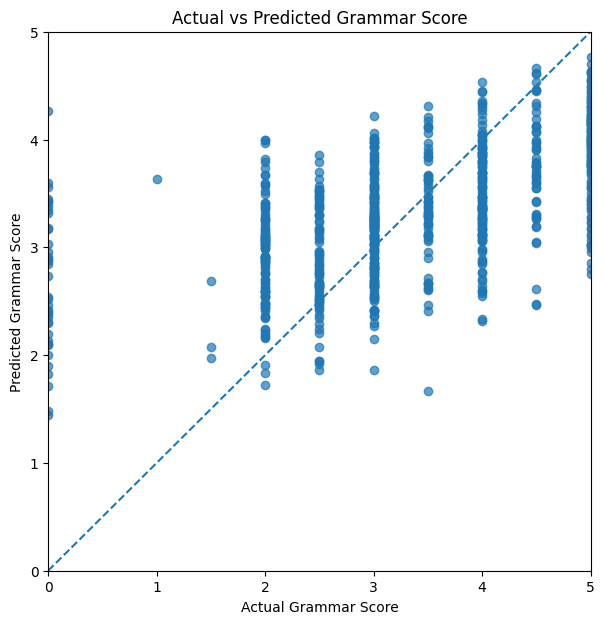

In [59]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y,
    best_oof,
    alpha=0.7
)

plt.plot(
    [0, 5],
    [0, 5],
    linestyle="--"
)

plt.xlabel("Actual Grammar Score")
plt.ylabel("Predicted Grammar Score")

plt.title(
    "Actual vs Predicted Grammar Score"
)

plt.xlim(0, 5)
plt.ylim(0, 5)

plt.show()

## Residual Analysis

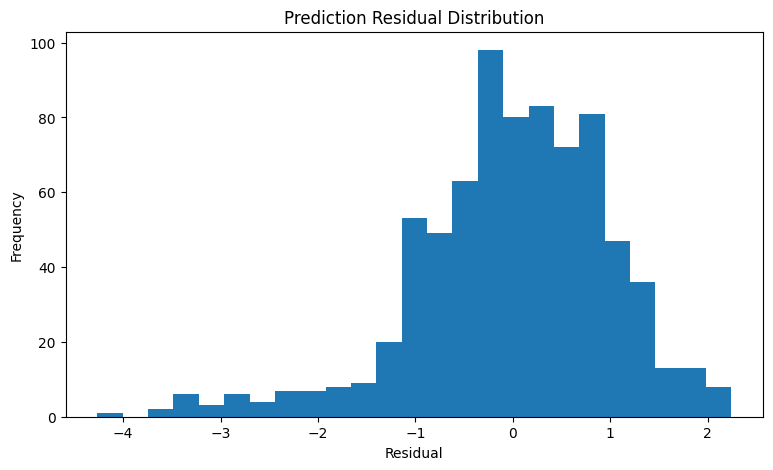

In [60]:
residuals = y - best_oof

plt.figure(figsize=(9, 5))

plt.hist(
    residuals,
    bins=25
)

plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.title(
    "Prediction Residual Distribution"
)

plt.show()

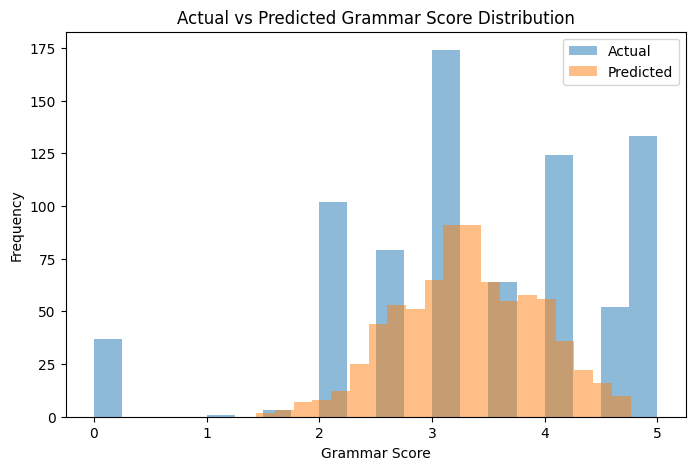

In [75]:
# Actual vs Predicted Score Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    y,
    bins=20,
    alpha=0.5,
    label="Actual"
)

plt.hist(
    best_oof,
    bins=20,
    alpha=0.5,
    label="Predicted"
)

plt.xlabel("Grammar Score")
plt.ylabel("Frequency")
plt.title("Actual vs Predicted Grammar Score Distribution")
plt.legend()

plt.show()

## Train final lightGBM on all 769 samples

In [61]:
X_full_lgbm = np.hstack([
    train_ling.values,
    train_embeddings
])

X_test_lgbm = np.hstack([
    test_ling.values,
    test_embeddings
])

final_lgbm = create_lgbm()

final_lgbm.fit(
    X_full_lgbm,
    y
)

test_pred_lgbm = final_lgbm.predict(
    X_test_lgbm
)

test_pred_lgbm = np.clip(
    test_pred_lgbm,
    0,
    5
)

## Train Final Ridge Model

In [62]:
all_train_text = train_transcripts[
    "transcript"
].fillna("")

all_test_text = test_transcripts[
    "transcript"
].fillna("")

In [63]:
final_word_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=15000,
    sublinear_tf=True
)

X_word_full = final_word_vectorizer.fit_transform(
    all_train_text
)

X_word_test = final_word_vectorizer.transform(
    all_test_text
)

In [64]:
final_char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=10000,
    sublinear_tf=True
)

X_char_full = final_char_vectorizer.fit_transform(
    all_train_text
)

X_char_test = final_char_vectorizer.transform(
    all_test_text
)

In [65]:
X_full_ridge = hstack([
    X_word_full,
    X_char_full
])

X_test_ridge = hstack([
    X_word_test,
    X_char_test
])

In [66]:
final_ridge = Ridge(
    alpha=10.0
)

final_ridge.fit(
    X_full_ridge,
    y
)

test_pred_ridge = final_ridge.predict(
    X_test_ridge
)

test_pred_ridge = np.clip(
    test_pred_ridge,
    0,
    5
)

## Final Ensemble Prediction

In [67]:
final_test_prediction = (
    best_weight * test_pred_lgbm
    +
    (1 - best_weight) * test_pred_ridge
)

final_test_prediction = np.clip(
    final_test_prediction,
    0,
    5
)

print(
    final_test_prediction[:20]
)

print(
    "Min:",
    final_test_prediction.min()
)

print(
    "Max:",
    final_test_prediction.max()
)

print(
    "Mean:",
    final_test_prediction.mean()
)

[3.57952505 2.73025296 4.16363769 2.42545788 2.20440368 3.35789216
 3.57745672 1.88887368 2.76312754 3.17768798 3.31401607 2.32077756
 2.27197532 2.12528768 3.75629184 2.88100857 3.23189988 3.7328314
 2.41861684 3.01118316]
Min: 1.2446764900069258
Max: 4.781002978365903
Mean: 3.093192971583384


In [78]:
# Validate final test predictions

print("Number of test predictions:", len(final_test_prediction))
print("Minimum prediction:", final_test_prediction.min())
print("Maximum prediction:", final_test_prediction.max())
print("Mean prediction:", final_test_prediction.mean())
print("Missing predictions:", np.isnan(final_test_prediction).sum())

assert len(final_test_prediction) == len(test)
assert not np.isnan(final_test_prediction).any()
assert np.all(
    (final_test_prediction >= 0) &
    (final_test_prediction <= 5)
)

Number of test predictions: 216
Minimum prediction: 1.2446764900069258
Maximum prediction: 4.781002978365903
Mean prediction: 3.093192971583384
Missing predictions: 0


## Training RMSE

In [76]:
# Predictions on the full training data
# Used to report the training-data RMSE required by the competition

train_pred_lgbm = final_lgbm.predict(
    X_full_lgbm
)

train_pred_ridge = final_ridge.predict(
    X_full_ridge
)

train_pred_lgbm = np.clip(
    train_pred_lgbm,
    0,
    5
)

train_pred_ridge = np.clip(
    train_pred_ridge,
    0,
    5
)

train_final_prediction = (
    best_weight * train_pred_lgbm
    +
    (1 - best_weight) * train_pred_ridge
)

train_final_prediction = np.clip(
    train_final_prediction,
    0,
    5
)

training_rmse = np.sqrt(
    mean_squared_error(
        y,
        train_final_prediction
    )
)

training_pearson = pearsonr(
    y,
    train_final_prediction
)[0]

print("=" * 50)
print("TRAINING DATA PERFORMANCE")
print("=" * 50)

print(f"Training RMSE:    {training_rmse:.4f}")
print(f"Training Pearson: {training_pearson:.4f}")

print("\n5-Fold OOF PERFORMANCE")
print("=" * 50)

print(f"OOF RMSE:         {final_cv_rmse:.4f}")
print(f"OOF Pearson:      {final_cv_pearson:.4f}")

TRAINING DATA PERFORMANCE
Training RMSE:    0.2976
Training Pearson: 0.9875

5-Fold OOF PERFORMANCE
OOF RMSE:         1.0062
OOF Pearson:      0.5906


## Final Results Summary

In [77]:
# Final Experiment Summary

final_results = pd.DataFrame({
    "Metric": [
        "Training RMSE",
        "Training Pearson",
        "5-Fold OOF RMSE",
        "5-Fold OOF Pearson",
        "LightGBM Weight",
        "Ridge Weight"
    ],
    "Value": [
        training_rmse,
        training_pearson,
        final_cv_rmse,
        final_cv_pearson,
        best_weight,
        1 - best_weight
    ]
})

display(final_results)

,Metric,Value
0,Training RMSE,0.297582
1,Training Pearson,0.987515
2,5-Fold OOF RMSE,1.006196
3,5-Fold OOF Pearson,0.590571
4,LightGBM Weight,0.900000
5,Ridge Weight,0.100000


## Create Submission

In [68]:
print(sample_submission.columns.tolist())
display(sample_submission.head())

['filename', 'label']


,filename,label
0,audio_804.wav,-1
1,audio_1028.wav,-1
2,audio_865.wav,-1
3,audio_774.wav,-1
4,audio_1138.wav,-1


In [69]:
# Create submission using ALL test files
submission = test[["filename"]].copy()

# Add the 216 model predictions
submission["label"] = final_test_prediction

# Check before saving
print("Submission shape:", submission.shape)
print("Test shape:", test.shape)
print("Prediction count:", len(final_test_prediction))

display(submission.head(10))

Submission shape: (216, 2)
Test shape: (216, 3)
Prediction count: 216


,filename,label
0,audio_128.wav,3.579525
1,audio_156.wav,2.730253
2,audio_19.wav,4.163638
3,audio_108.wav,2.425458
4,audio_206.wav,2.204404
5,audio_161.wav,3.357892
6,audio_215.wav,3.577457
7,audio_213.wav,1.888874
8,audio_11.wav,2.763128
9,audio_155.wav,3.177688


In [70]:
submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

print("Submission created successfully!")

Submission created successfully!


In [71]:
submission_check = pd.read_csv(
    "/kaggle/working/submission.csv"
)

print(submission_check.shape)
print(submission_check.columns.tolist())
display(submission_check.head())

(216, 2)
['filename', 'label']


,filename,label
0,audio_128.wav,3.579525
1,audio_156.wav,2.730253
2,audio_19.wav,4.163638
3,audio_108.wav,2.425458
4,audio_206.wav,2.204404


In [79]:
# Final submission validation

assert submission_check.shape == (216, 2)

assert submission_check.columns.tolist() == [
    "filename",
    "label"
]

assert submission_check["filename"].notna().all()

assert submission_check["label"].notna().all()

assert submission_check["label"].between(
    0,
    5
).all()

assert submission_check["filename"].nunique() == 216

print("✓ Submission shape is correct")
print("✓ Columns are correct")
print("✓ No missing filenames")
print("✓ No missing predictions")
print("✓ All predictions are within [0, 5]")
print("✓ 216 unique test files included")

✓ Submission shape is correct
✓ Columns are correct
✓ No missing filenames
✓ No missing predictions
✓ All predictions are within [0, 5]
✓ 216 unique test files included


# Final Methodology


## Objective

The objective is to predict a continuous Grammar Score between 0 and 5 for spoken English audio samples.

## Dataset

- Training samples: 769
- Test samples: 216
- Audio duration: approximately 45–60 seconds
- Training labels: human-provided grammar scores
- Test labels: unavailable/dummy value (-1)

## Proposed Pipeline

Audio
↓
Whisper Small English
↓
Speech Transcript
↓
Feature Extraction

Three types of textual information were used:

1. Linguistic and syntactic features
   - sentence count
   - sentence length
   - lexical diversity
   - POS ratios
   - dependency depth
   - syntactic structure

2. TF-IDF features
   - word n-grams
   - character n-grams

3. Sentence embeddings
   - all-MiniLM-L6-v2

## Models

Two regression models were trained:

- LightGBM using linguistic features and sentence embeddings
- Ridge regression using word- and character-level TF-IDF features

The predictions of the two models were combined using a weight selected using the OOF validation predictions.

## Evaluation

Five-fold cross-validation was used on the 769 labeled training samples.

Evaluation metrics:

- RMSE — lower is better
- Pearson Correlation — higher is better

## Final Prediction

The final model was trained using all available training samples and used to generate predictions for the 216 test audio samples.

Predictions were constrained to the valid range [0, 5].

## Submission

The final submission contains:

- filename
- predicted label

for all 216 test audio files.